# デジタル宇宙論 実証シミュレーション (v2.0)

本ノートブックは、Digital Cosmology v2.0 仕様（`Vol.1`〜`Vol.3`, `Kernel_01`〜`05`, `Experiment_Proposal.md` v2.0）に基づく数値シミュレーションおよびデータ解析プロトコルの実証コードです。

- **Section 1:** デジタル干渉（整数位相カウンタ加算）
- **Section 2:** 量子消しゴム（事後SQLフィルタリング）
- **Section 3:** 離散スロットリング段数 $k(x)$ による不感帯・基準高度シフト検定、および `Kernel_05` 高負荷ソフトエラーモデル
- **Section 4:** `Project "Step-Finder"` 感度解析・線形回帰残差（ノコギリ波）FFT検定・BICモデル選択パイプライン

In [1]:
# 必要なライブラリのインポート
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# グラフのスタイル設定
plt.style.use('seaborn-v0_8-darkgrid')

## 1. デジタル干渉と位相加算 (Digital Interference)

「波」を使わず、整数の位相カウンタの加算のみで干渉縞（確率分布）を生成するロジックの実証。

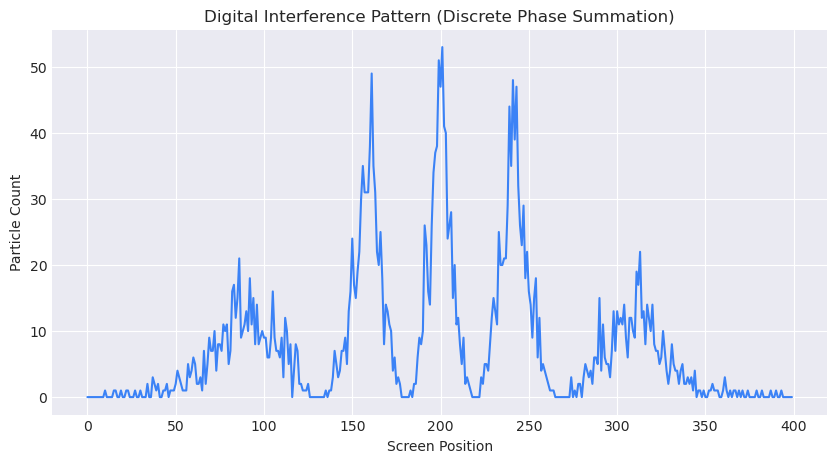

In [2]:
def digital_interference_simulation(num_particles=20000, screen_width=400, seed=42):
    rng = np.random.default_rng(seed)
    screen = np.zeros(screen_width)

    # 離散的な位相の最大値 (ビット深度に相当)
    PHASE_MAX = 100
    WAVELENGTH_FACTOR = 15.0

    for _ in range(num_particles):
        x = rng.integers(0, screen_width)

        # スリットA, Bからの距離
        dist_a = np.sqrt((x - screen_width * 0.45) ** 2 + 100 ** 2)
        dist_b = np.sqrt((x - screen_width * 0.55) ** 2 + 100 ** 2)

        # 距離を離散的な位相カウンタに変換 (整数)
        phase_a = int(dist_a / WAVELENGTH_FACTOR * PHASE_MAX) % PHASE_MAX
        phase_b = int(dist_b / WAVELENGTH_FACTOR * PHASE_MAX) % PHASE_MAX

        # 位相の差分（逆位相なら0、同位相なら1）
        phase_diff = abs(phase_a - phase_b)
        if phase_diff > PHASE_MAX / 2:
            phase_diff = PHASE_MAX - phase_diff

        interference_term = (1.0 - (phase_diff / (PHASE_MAX / 2))) ** 2

        # 中央集中のエンベロープ (回折の影響)
        center_dist = abs(x - screen_width / 2)
        diffraction_term = np.exp(- (center_dist / (screen_width * 0.25)) ** 2)

        prob = interference_term * diffraction_term

        # 確率的確定 (モンテカルロ法)
        if rng.random() < prob:
            screen[x] += 1

    return screen

result = digital_interference_simulation()
plt.figure(figsize=(10, 5))
plt.plot(result, color='#3b82f6')
plt.title("Digital Interference Pattern (Discrete Phase Summation)")
plt.xlabel("Screen Position")
plt.ylabel("Particle Count")
plt.show()

## 2. 量子消しゴム：データベース・フィルタリング (Quantum Eraser DB)

「未来が過去を変える」のではなく、検出器の結果を検索キーとした「事後的なクエリ（フィルタリング）」によって、隠れていたパターンが抽出されることを示します。

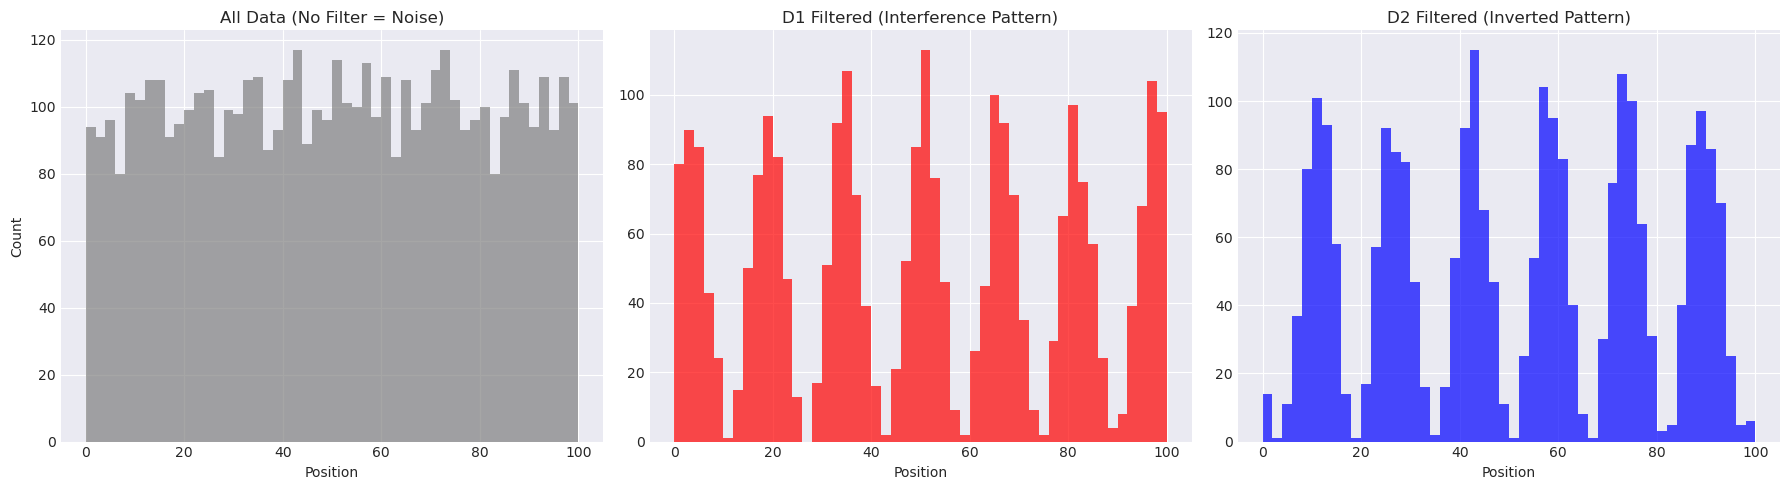

In [3]:
rng_qe = np.random.default_rng(42)
num_data = 5000
data = []

# 1. データ生成 (着弾時点: 過去)
for i in range(num_data):
    hidden_type = rng_qe.choice(['TypeA', 'TypeB'])

    if hidden_type == 'TypeA':
        while True:
            pos = rng_qe.integers(0, 100)
            prob = np.cos((pos - 50) * 0.2) ** 2
            if rng_qe.random() < prob:
                break
    else:
        while True:
            pos = rng_qe.integers(0, 100)
            prob = np.sin((pos - 50) * 0.2) ** 2
            if rng_qe.random() < prob:
                break

    data.append({'ID': i, 'Position': pos, 'HiddenTag': hidden_type})

df = pd.DataFrame(data)

# 2. 検出器による選別 (事後クエリ)
def query_detector(detector_name):
    if detector_name == 'D1':
        return df[df['HiddenTag'] == 'TypeA']
    elif detector_name == 'D2':
        return df[df['HiddenTag'] == 'TypeB']
    return df

# 3. 結果の表示 (0..99を均等に切るため bins=50 を使用)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df['Position'], bins=50, range=(0, 100), color='gray', alpha=0.7)
axes[0].set_title("All Data (No Filter = Noise)")
axes[0].set_xlabel("Position")
axes[0].set_ylabel("Count")

d1_results = query_detector('D1')
axes[1].hist(d1_results['Position'], bins=50, range=(0, 100), color='red', alpha=0.7)
axes[1].set_title("D1 Filtered (Interference Pattern)")
axes[1].set_xlabel("Position")

d2_results = query_detector('D2')
axes[2].hist(d2_results['Position'], bins=50, range=(0, 100), color='blue', alpha=0.7)
axes[2].set_title("D2 Filtered (Inverted Pattern)")
axes[2].set_xlabel("Position")

plt.tight_layout()
plt.show()

## 3. 重力赤方偏移の「不感帯」(v2.0 段数 $k(x)$ モデル) と高負荷ソフトエラー (`Kernel_05`)

### 3.1 地点段数 $k(h)$ モデル・推移律検証・基準高度シフト検定 (`Kernel_03` v2.0)
重力赤方偏移を2点間の差分に対する直接の床関数ではなく、各地点 $h$ の離散スロットリング段数
$$k(h) = \left\lfloor \frac{\Phi_{\text{load}}(h) / c^2}{\delta Z_{\text{local}}} \right\rfloor$$
の差 $\frac{\Delta f_{\text{clock}}}{f_0} = (k(h_1) - k(h_2)) \cdot \delta Z_{\text{local}}$ として実装します。

*(注：以下の $\delta Z_{\text{local}} = 1.0 \times 10^{-18}$ は光格子時計の感度帯における**探索用の仮置きパラメータ**であり、理論が絶対値として固定予言する値ではありません。)*

=== Transitivity Verification (A -> B -> C vs A -> C) ===
Step Height Δh_step = 9.165 mm (at δZ_local = 1.0e-18)
[v2.0 k(h) Model] s(A,B)+s(B,C) = 1.000e-18 | s(A,C) = 1.000e-18 | Consistent: True
[Legacy Δh Model] s(A,B)+s(B,C) = 0.000e+00 | s(A,C) = 1.000e-18 | Consistent: True


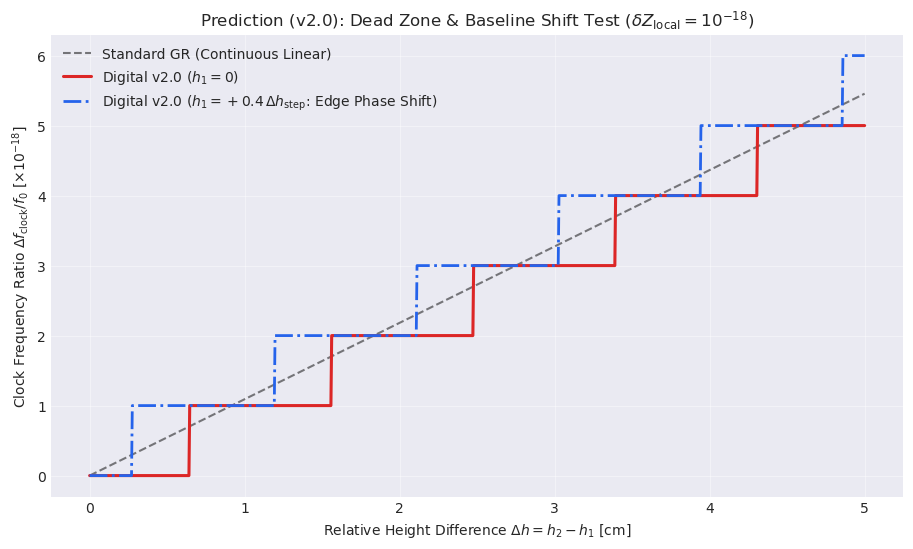

In [4]:
# 物理定数（近似マッピングツール）
G_ACCEL = 9.80665        # 地表重力加速度 [m/s^2]
C_LIGHT = 2.99792458e8   # 光速 [m/s]
GRADIENT = G_ACCEL / (C_LIGHT ** 2)  # 約 1.0911e-16 [1/m]

def throttling_level(h, delta_z, phi0_phase=0.7):
    """
    各地点の高度 h [m] における離散スロットリング段数 k(h) を返す。
    高度が上がるほど重力負荷深さ Phi_load(h) は減少する。
    phi0_phase in [0, 1) は基準高度 h=0 における端数位相（背景ポテンシャル由来）。
    """
    u = phi0_phase - (GRADIENT * h) / delta_z
    return np.floor(u).astype(np.int64)

def discrete_clock_shift(h1, h2, delta_z, phi0_phase=0.7):
    """
    2地点 h1 (基準時計) と h2 (測定時計) の相対周波数比 (f(h2) - f(h1)) / f0。
    h2 > h1 のとき上方の時計が速く進むため非負となる。
    """
    return (throttling_level(h1, delta_z, phi0_phase) - throttling_level(h2, delta_z, phi0_phase)) * delta_z

def simulate_discrete_redshift_v2():
    # 探索用パラメータ（仮置き）
    DELTA_Z_LOCAL = 1.0e-18
    PHI0_PHASE = 0.70  # h=0 における初期端数位相
    dh_step = DELTA_Z_LOCAL / GRADIENT  # 1段あたりの高度幅 ≈ 9.16 mm

    # --- 1. 推移律 (Transitivity) の数値検証 ---
    hA, hB, hC = 0.0, 0.6 * dh_step, 1.2 * dh_step
    s_ab = discrete_clock_shift(hA, hB, DELTA_Z_LOCAL, PHI0_PHASE)
    s_bc = discrete_clock_shift(hB, hC, DELTA_Z_LOCAL, PHI0_PHASE)
    s_ac = discrete_clock_shift(hA, hC, DELTA_Z_LOCAL, PHI0_PHASE)

    # 比較用：旧モデル（差分に直接 floor をかける推移律違反モデル）
    old_shift = lambda d: np.floor((GRADIENT * d) / DELTA_Z_LOCAL) * DELTA_Z_LOCAL
    old_ab, old_bc, old_ac = old_shift(hB - hA), old_shift(hC - hB), old_shift(hC - hA)

    print("=== Transitivity Verification (A -> B -> C vs A -> C) ===")
    print(f"Step Height Δh_step = {dh_step * 1e3:.3f} mm (at δZ_local = {DELTA_Z_LOCAL:.1e})")
    print(f"[v2.0 k(h) Model] s(A,B)+s(B,C) = {(s_ab + s_bc):.3e} | s(A,C) = {s_ac:.3e} | Consistent: {np.isclose(s_ab + s_bc, s_ac)}")
    print(f"[Legacy Δh Model] s(A,B)+s(B,C) = {(old_ab + old_bc):.3e} | s(A,C) = {old_ac:.3e} | Consistent: {np.isclose(old_ab + old_bc, old_ac)}")

    # --- 2. 基準高度シフト検定 (Baseline Offset Test) ---
    delta_h = np.linspace(0.0, 0.05, 1000)  # 相対高度差 0 ~ 5 cm
    h1_base = 0.0
    h1_shifted = 0.4 * dh_step  # 基準時計を 0.4 ステップ分だけ上にずらす

    shift_standard = GRADIENT * delta_h
    shift_v2_base = discrete_clock_shift(h1_base, h1_base + delta_h, DELTA_Z_LOCAL, PHI0_PHASE)
    shift_v2_offset = discrete_clock_shift(h1_shifted, h1_shifted + delta_h, DELTA_Z_LOCAL, PHI0_PHASE)

    plt.figure(figsize=(11, 6))
    plt.plot(delta_h * 100, shift_standard * 1e18, 'k--', alpha=0.5, label='Standard GR (Continuous Linear)')
    plt.plot(delta_h * 100, shift_v2_base * 1e18, color='#dc2626', linewidth=2.2,
             label=r'Digital v2.0 ($h_1 = 0$)')
    plt.plot(delta_h * 100, shift_v2_offset * 1e18, color='#2563eb', linewidth=2.0, linestyle='-.',
             label=r'Digital v2.0 ($h_1 = +0.4\,\Delta h_{\mathrm{step}}$: Edge Phase Shift)')

    plt.title(r"Prediction (v2.0): Dead Zone & Baseline Shift Test ($\delta Z_{\mathrm{local}} = 10^{-18}$)")
    plt.xlabel(r"Relative Height Difference $\Delta h = h_2 - h_1$ [cm]")
    plt.ylabel(r"Clock Frequency Ratio $\Delta f_{\mathrm{clock}} / f_0$ [$\times 10^{-18}$]")
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

simulate_discrete_redshift_v2()

### 3.2 高負荷スレッドにおけるソフトエラー発生率 (`Kernel_05` v2.0)
演算負荷率 $\rho_{\text{op}} \in [0, \rho_{\max}]$ がハードウェア上限へ飽和するにつれ、総エネルギー殻保存 $F(S_E) \subseteq S_E$ の枠内で非決定的なビット反転（ソフトエラー）の発生確率
$$P_{\text{error}}(\rho_{\text{op}}) = P_0 \exp\left(\frac{\rho_{\text{op}} - \rho_{\max}}{\sigma}\right)$$
が指数関数的に急増する挙動を可視化します。

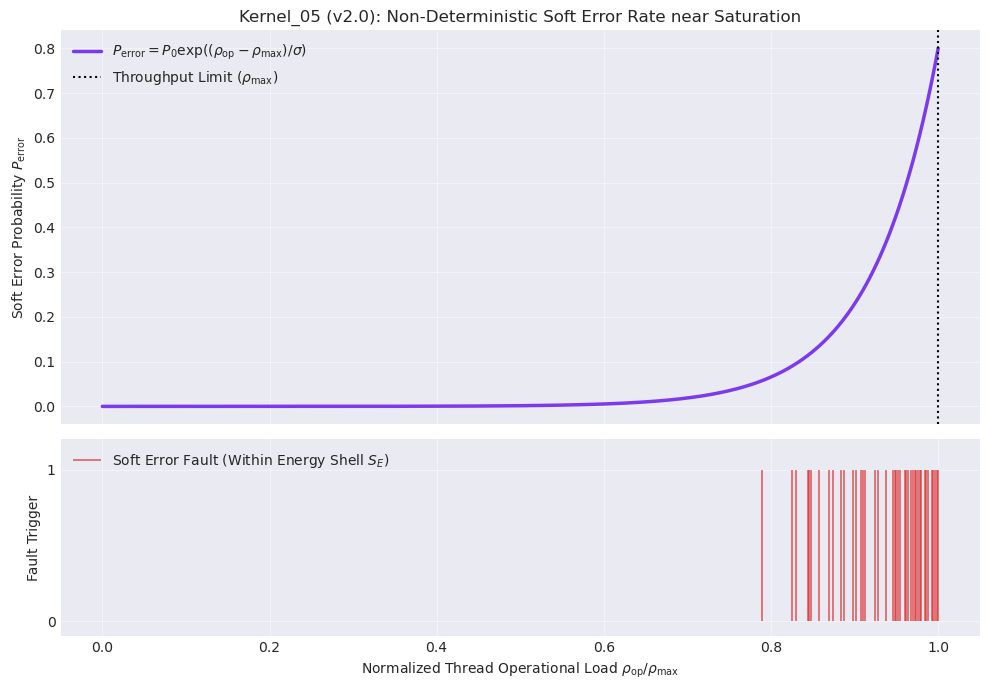

In [5]:
def simulate_soft_error_rate(seed=42):
    rng = np.random.default_rng(seed)

    RHO_MAX = 1.0   # 単一スレッドのスループット上限（規格化）
    P0 = 0.8        # 飽和極限での最大エラー確率 (0 < P0 <= 1)
    SIGMA = 0.08    # ハードウェアの耐障害マージン幅

    rho_grid = np.linspace(0.0, RHO_MAX, 500)
    p_error = P0 * np.exp((rho_grid - RHO_MAX) / SIGMA)

    # モンテカルロ試行（各負荷点で1回試行したときのソフトエラー発生イベント）
    fault_events = (rng.random(len(rho_grid)) < p_error).astype(float)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    ax1.plot(rho_grid, p_error, color='#7c3aed', linewidth=2.5,
             label=r'$P_{\mathrm{error}} = P_0 \exp((\rho_{\mathrm{op}} - \rho_{\max}) / \sigma)$')
    ax1.axvline(x=RHO_MAX, color='black', linestyle=':', label=r'Throughput Limit ($\rho_{\max}$)')
    ax1.set_title("Kernel_05 (v2.0): Non-Deterministic Soft Error Rate near Saturation")
    ax1.set_ylabel("Soft Error Probability $P_{\mathrm{error}}$")
    ax1.legend()
    ax1.grid(True, alpha=0.4)

    # 発生イベントのスパイク表示
    event_rho = rho_grid[fault_events > 0]
    ax2.vlines(event_rho, 0, 1, color='#dc2626', alpha=0.7, linewidth=1.2, label='Soft Error Fault (Within Energy Shell $S_E$)')
    ax2.set_xlabel(r"Normalized Thread Operational Load $\rho_{\mathrm{op}} / \rho_{\max}$")
    ax2.set_ylabel("Fault Trigger")
    ax2.set_yticks([0, 1])
    ax2.set_ylim(-0.1, 1.2)
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.4)

    plt.tight_layout()
    plt.show()

simulate_soft_error_rate()

## 4. 感度解析および生データ残差検出パイプライン (`Experiment_Proposal.md` 4章準拠)

3つの測定精度シナリオを比較し、 **「単一点での $3\sigma$ 視認限界」** と **「平滑化前の多点生データに対する残差FFT・BICモデル選択による統計検出限界」** の違いを定量検証します。

1. **Scenario A (Standard Atomic Clock):** $\sigma = 5.0\,\delta Z_{\text{local}}$（単一点・多点統計ともに検出不能）
2. **Scenario B (Current Optical Lattice Clock):** $\sigma = 0.6\,\delta Z_{\text{local}}$（単一点 $3\sigma$ は不可だが、残差ノコギリ波のFFTピークと $\Delta\text{BIC}$ により統計的に検出可能）
3. **Scenario C (Next-Gen Optical Lattice Clock):** $\sigma = 0.1\,\delta Z_{\text{local}}$（単一点でも明瞭に階段と不感帯を視認可能）

**検出判定基準（偽陽性防止のための複合基準）：**
- 残差正規化パワースペクトル（独立正周波数ビン $M$ に対するボンフェローニ補正）で **$\text{FAP} < 0.001$**
- かつ、FFTピーク周波数から盲検推定した階段モデル（$k_{\text{step}}=3$: $\delta Z, \phi_0, b$）が線形モデル（$k_{\text{lin}}=2$: 傾き, 切片）に対して **$\Delta\text{BIC} = \text{BIC}_{\text{lin}} - \text{BIC}_{\text{step}} > 10$**

=== Project 'Step-Finder' Sensitivity & Residual Analysis Report ===
True Step: δZ_local = 1.00e-18 | Δh_step = 9.165 mm | True Freq = 109.11 cycles/m
Single-Point 3σ Threshold: σ < 3.333e-19

[Scenario A: Standard Atomic Clock] σ = 5.00e-18 (5.0 δZ)
  - Single-Point 3σ Visual: FAIL
  - Residual FFT Peak: z = 6.25 (Threshold = 13.12, FAP = 6.18e-01)
  - Model Selection: ΔBIC (Linear - Step) = -6.21 (> 10 required)
  - Blind Estimated δZ_local = 7.345e-20 (True = 1.000e-18) -> Final: NOT DETECTED

[Scenario B: Current Optical Clock] σ = 6.00e-19 (0.6 δZ)
  - Single-Point 3σ Visual: FAIL
  - Residual FFT Peak: z = 65.94 (Threshold = 13.12, FAP = 0.00e+00)
  - Model Selection: ΔBIC (Linear - Step) = 162.17 (> 10 required)
  - Blind Estimated δZ_local = 1.003e-18 (True = 1.000e-18) -> Final: DETECTED

[Scenario C: Next-Gen Optical Clock] σ = 1.00e-19 (0.1 δZ)
  - Single-Point 3σ Visual: PASS
  - Residual FFT Peak: z = 264.26 (Threshold = 13.12, FAP = 0.00e+00)
  - Model Selection: ΔBIC (Li

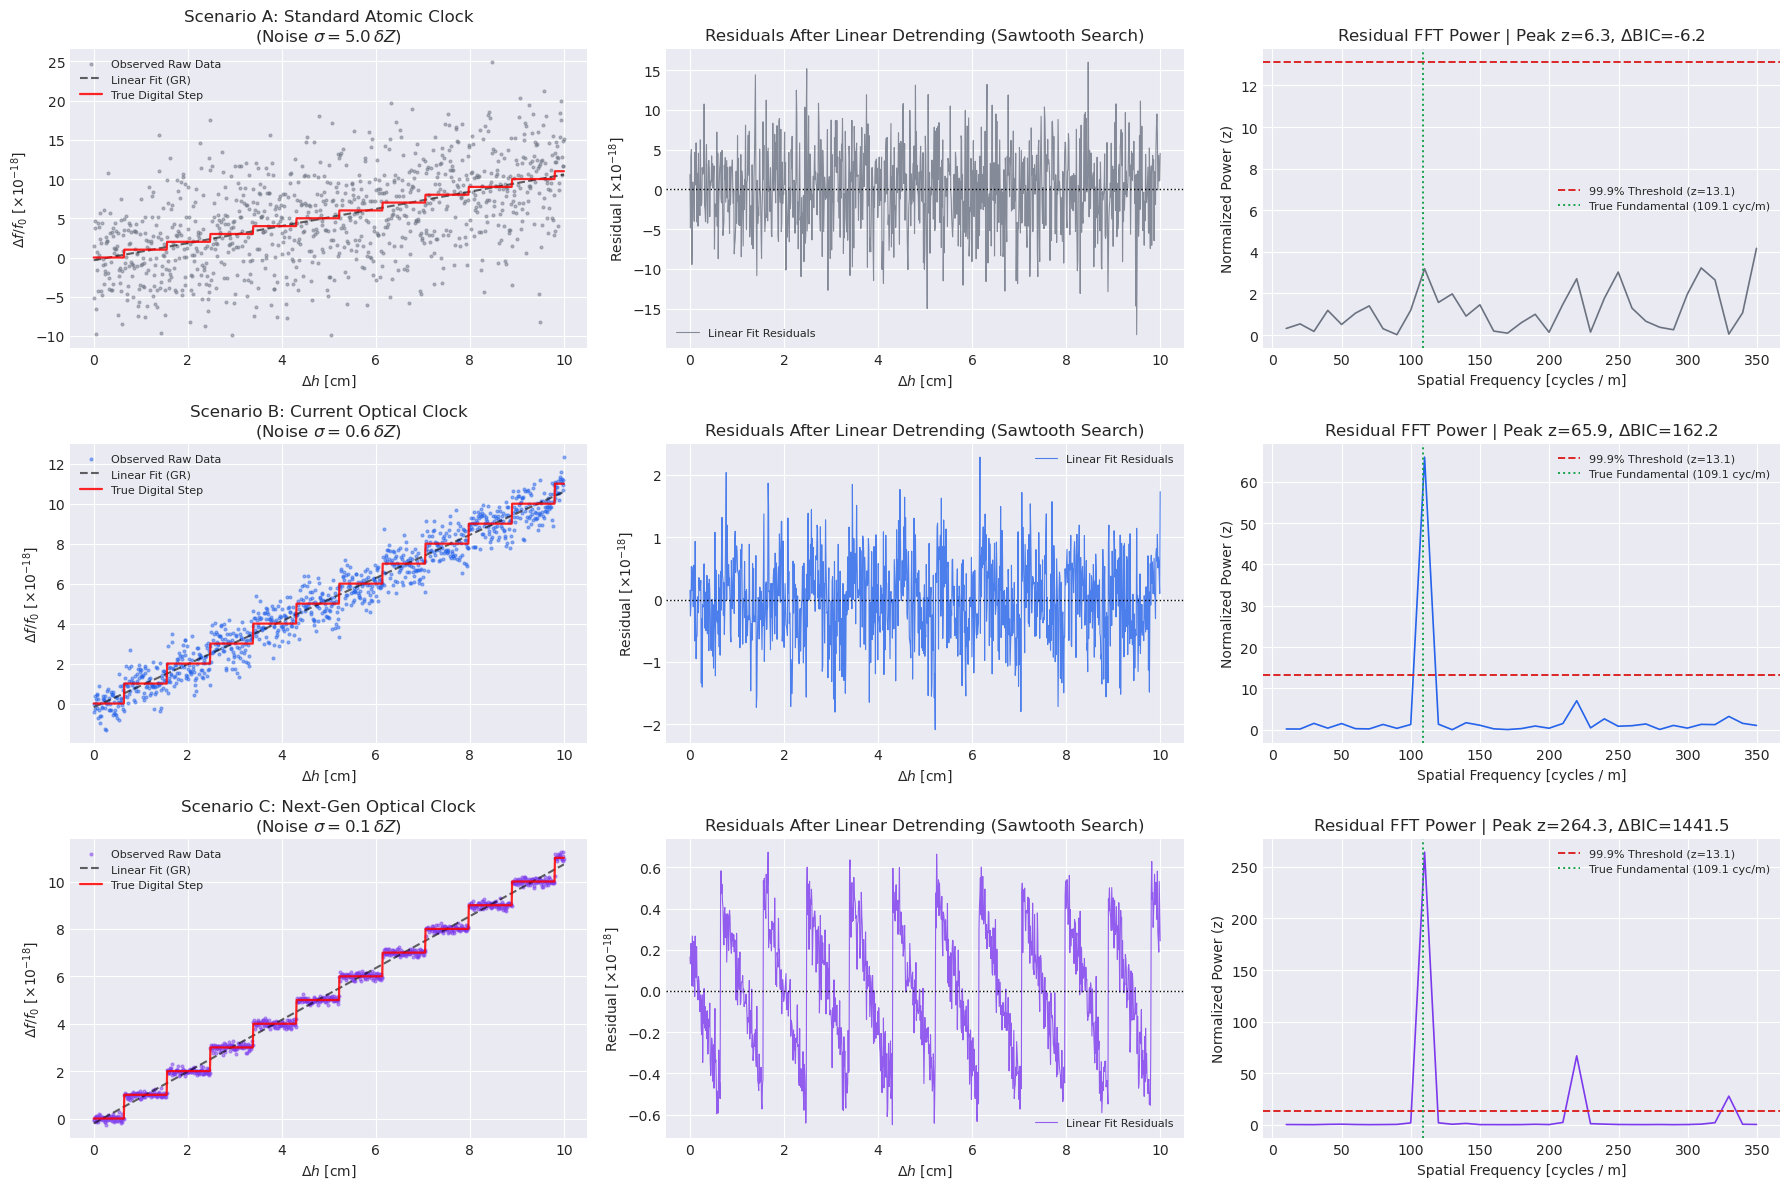

In [6]:
def analyze_redshift_dataset(delta_h, y_obs, true_delta_z, noise_sigma):
    """
    Experiment_Proposal.md 4章準拠の残差スペクトル解析＆BICモデル選択パイプライン。
    真のパラメータを一切使わず、観測データ (delta_h, y_obs) のみから階段構造を検定する。
    """
    N = len(delta_h)
    dh_sample = delta_h[1] - delta_h[0]

    # 1. 線形回帰と残差抽出 (Linear Detrending -> Sawtooth Residual)
    slope_lin, intercept_lin = np.polyfit(delta_h, y_obs, 1)
    y_lin_fit = slope_lin * delta_h + intercept_lin
    residuals = y_obs - y_lin_fit
    rss_lin = np.sum(residuals ** 2)
    bic_lin = N * np.log(rss_lin / N) + 2 * np.log(N)  # k_lin = 2

    # 2. 残差の正規化FFTパワースペクトル検定 (Bonferroni FAP)
    # 独立な正周波数ビン k = 1 .. N//2 - 1 のみを使用（DCとナイキスト端を除外）
    fft_vals = np.fft.rfft(residuals)
    freqs = np.fft.rfftfreq(N, d=dh_sample)  # [cycles / m]

    pos_freqs = freqs[1:-1]
    pos_power_raw = np.abs(fft_vals[1:-1]) ** 2
    res_var = np.var(residuals)
    norm_power = pos_power_raw / (N * res_var)  # 白色ノイズ下で平均1の Exp(1) に従う

    M = len(pos_freqs)
    fap_alpha = 0.001  # 99.9% 信頼水準
    # 1 - (1 - exp(-z))^M = alpha  =>  z_th = -ln(1 - (1 - alpha)^(1/M))
    z_threshold = -np.log(1.0 - (1.0 - fap_alpha) ** (1.0 / M))

    peak_idx = int(np.argmax(norm_power))
    peak_freq = pos_freqs[peak_idx]
    peak_power = norm_power[peak_idx]
    fap_value = 1.0 - (1.0 - np.exp(-min(peak_power, 700.0))) ** M

    # 3. FFTピーク周波数から盲検プロファイル最尤推定で階段モデルをフィット
    # 候補ステップ幅 δZ = (g/c^2) / f_peak の周囲 ±15% と位相 φ0 ∈ [0, 1) を探索
    dz_center = GRADIENT / peak_freq
    dz_candidates = np.linspace(dz_center * 0.85, dz_center * 1.15, 61)
    phase_candidates = np.linspace(0.0, 1.0, 40, endpoint=False)

    best_rss_step = np.inf
    best_params = (dz_center, 0.0, 0.0)

    for dz_cand in dz_candidates:
        # (40, N) のブロードキャストで全位相を一括評価
        u_mat = phase_candidates[:, None] - (GRADIENT * delta_h[None, :]) / dz_cand
        k0_vec = np.floor(phase_candidates)  # 常に 0
        step_mat = (k0_vec[:, None] - np.floor(u_mat)) * dz_cand
        # 各候補に対する最適切片 b* = mean(y_obs - step_model)
        b_vec = np.mean(y_obs[None, :] - step_mat, axis=1)
        err_mat = y_obs[None, :] - (step_mat + b_vec[:, None])
        rss_vec = np.sum(err_mat ** 2, axis=1)

        min_p_idx = int(np.argmin(rss_vec))
        if rss_vec[min_p_idx] < best_rss_step:
            best_rss_step = rss_vec[min_p_idx]
            best_params = (dz_cand, phase_candidates[min_p_idx], b_vec[min_p_idx])

    bic_step = N * np.log(best_rss_step / N) + 3 * np.log(N)  # k_step = 3 (dz, phase, offset)
    delta_bic = bic_lin - bic_step  # 正で大きいほど階段モデルが優位

    single_point_ok = noise_sigma < (true_delta_z / 3.0)
    stat_detected = (peak_power > z_threshold) and (delta_bic > 10.0)

    return {
        'residuals': residuals,
        'y_lin_fit': y_lin_fit,
        'pos_freqs': pos_freqs,
        'norm_power': norm_power,
        'z_threshold': z_threshold,
        'peak_freq': peak_freq,
        'peak_power': peak_power,
        'fap_value': fap_value,
        'est_delta_z': best_params[0],
        'delta_bic': delta_bic,
        'single_point_ok': single_point_ok,
        'stat_detected': stat_detected,
    }

def run_sensitivity_pipeline(seed=42):
    rng = np.random.default_rng(seed)

    # 真の探索設定（仮置きパラメータ）
    TRUE_DELTA_Z = 1.0e-18
    TRUE_PHI0 = 0.70
    TRUE_DH_STEP = TRUE_DELTA_Z / GRADIENT   # ≈ 9.165 mm
    TRUE_FREQ = 1.0 / TRUE_DH_STEP           # ≈ 109.12 cycles/m

    # 掃引レンジ：0 ~ 10 cm を 1000 点サンプリング (0.1 mm 刻み)
    delta_h = np.linspace(0.0, 0.10, 1000)
    signal_true = discrete_clock_shift(0.0, delta_h, TRUE_DELTA_Z, TRUE_PHI0)

    scenarios = [
        ("Scenario A: Standard Atomic Clock", 5.0 * TRUE_DELTA_Z, '#6b7280'),
        ("Scenario B: Current Optical Clock", 0.6 * TRUE_DELTA_Z, '#2563eb'),
        ("Scenario C: Next-Gen Optical Clock", 0.1 * TRUE_DELTA_Z, '#7c3aed'),
    ]

    fig, axes = plt.subplots(3, 3, figsize=(18, 12))

    print("=== Project 'Step-Finder' Sensitivity & Residual Analysis Report ===")
    print(f"True Step: δZ_local = {TRUE_DELTA_Z:.2e} | Δh_step = {TRUE_DH_STEP*1e3:.3f} mm | True Freq = {TRUE_FREQ:.2f} cycles/m")
    print(f"Single-Point 3σ Threshold: σ < {TRUE_DELTA_Z/3.0:.3e}\n")

    for row, (name, sigma, color) in enumerate(scenarios):
        y_obs = signal_true + rng.normal(0.0, sigma, size=len(delta_h))
        res = analyze_redshift_dataset(delta_h, y_obs, TRUE_DELTA_Z, sigma)

        # 列1: 生データと真の階段信号
        ax_raw = axes[row, 0]
        ax_raw.scatter(delta_h * 100, y_obs * 1e18, s=4, alpha=0.45, color=color, label='Observed Raw Data')
        ax_raw.plot(delta_h * 100, res['y_lin_fit'] * 1e18, 'k--', alpha=0.6, label='Linear Fit (GR)')
        ax_raw.plot(delta_h * 100, signal_true * 1e18, 'r-', linewidth=1.6, alpha=0.85, label='True Digital Step')
        ax_raw.set_title(f"{name}\n(Noise $\\sigma = {sigma/TRUE_DELTA_Z:.1f}\\,\\delta Z$)")
        ax_raw.set_xlabel(r"$\Delta h$ [cm]")
        ax_raw.set_ylabel(r"$\Delta f / f_0$ [$\times 10^{-18}$]")
        ax_raw.legend(fontsize=8)

        # 列2: 線形回帰残差（ノコギリ波の抽出）
        ax_res = axes[row, 1]
        ax_res.plot(delta_h * 100, res['residuals'] * 1e18, color=color, linewidth=0.8, alpha=0.8, label='Linear Fit Residuals')
        ax_res.axhline(0, color='black', linestyle=':', linewidth=1)
        ax_res.set_title("Residuals After Linear Detrending (Sawtooth Search)")
        ax_res.set_xlabel(r"$\Delta h$ [cm]")
        ax_res.set_ylabel(r"Residual [$\times 10^{-18}$]")
        ax_res.legend(fontsize=8)

        # 列3: 残差の正規化FFTパワースペクトル
        ax_fft = axes[row, 2]
        freq_mask = res['pos_freqs'] <= 350.0  # 基本波と2〜3倍高調波を表示
        ax_fft.plot(res['pos_freqs'][freq_mask], res['norm_power'][freq_mask], color=color, linewidth=1.2)
        ax_fft.axhline(res['z_threshold'], color='#dc2626', linestyle='--', linewidth=1.4,
                       label=f"99.9% Threshold (z={res['z_threshold']:.1f})")
        ax_fft.axvline(TRUE_FREQ, color='#16a34a', linestyle=':', linewidth=1.4,
                       label=f"True Fundamental ({TRUE_FREQ:.1f} cyc/m)")
        ax_fft.set_title(f"Residual FFT Power | Peak z={res['peak_power']:.1f}, $\\Delta$BIC={res['delta_bic']:.1f}")
        ax_fft.set_xlabel("Spatial Frequency [cycles / m]")
        ax_fft.set_ylabel("Normalized Power (z)")
        ax_fft.legend(fontsize=8)

        status = "DETECTED" if res['stat_detected'] else "NOT DETECTED"
        print(f"[{name}] σ = {sigma:.2e} ({sigma/TRUE_DELTA_Z:.1f} δZ)")
        print(f"  - Single-Point 3σ Visual: {'PASS' if res['single_point_ok'] else 'FAIL'}")
        print(f"  - Residual FFT Peak: z = {res['peak_power']:.2f} (Threshold = {res['z_threshold']:.2f}, FAP = {res['fap_value']:.2e})")
        print(f"  - Model Selection: ΔBIC (Linear - Step) = {res['delta_bic']:.2f} (> 10 required)")
        print(f"  - Blind Estimated δZ_local = {res['est_delta_z']:.3e} (True = {TRUE_DELTA_Z:.3e}) -> Final: {status}\n")

    plt.tight_layout()
    plt.show()

run_sensitivity_pipeline()